In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mutual_info_score, accuracy_score, recall_score, roc_auc_score
from sklearn.linear_model import LogisticRegression

In [32]:
df = pd.read_csv('ckd.csv')
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [33]:
df.nunique().sort_values(ascending=False)

bgr      146
bu       118
hemo     115
wbcc      89
sc        84
age       76
rbcc      45
pcv       42
pot       40
sod       34
bp        10
al         6
su         6
sg         5
dm         3
class      3
rbc        2
ba         2
pcc        2
pc         2
htn        2
cad        2
appet      2
pe         2
ane        2
dtype: int64

In [34]:
df = df.rename(columns={
    "bp": "blood_pressure",
    "sg": "urine_specific_gravity",
    "al": "urine_albumin_level",
    "su": "urine_sugar_level",
    "rbc": "red_blood_cell_status",
    "pc": "pus_cell_status",
    "pcc": "pus_cell_clumps",
    "ba": "bacteria",
    "bgr": "random_blood_glucose",
    "bu": "blood_urea",
    "sc": "serum_creatinine",
    "sod": "sodium",
    "pot": "potassium",
    "hemo": "hemoglobin",
    "pcv": "packed_cell_volume",
    "wc": "white_blood_cell_count",
    "wbcc": "white_blood_cell_count",
    "rc": "red_blood_cell_count",
    "rbcc": "red_blood_cell_count",
    "htn": "hypertension",
    "dm": "diabetes_mellitus",
    "cad": "coronary_artery_disease",
    "appet": "appetite",
    "pe": "pedal_edema",
    "ane": "anemia",
    "class": "ckd_status"
})

In [35]:
catergorical_columns = list(
    df.select_dtypes(include=["object", "string", "category"]).columns
)

print(catergorical_columns)
print(len(catergorical_columns))

['red_blood_cell_status', 'pus_cell_status', 'pus_cell_clumps', 'bacteria', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'pedal_edema', 'anemia', 'ckd_status']
11


In [36]:
for c in catergorical_columns:
    df[c] = (
        df[c]
        .astype("str")
        .str.lower()
        .str.strip()
        .replace({"?": pd.NA, "": pd.NA}) #without gpt I would not have any idea this even exists
    )

In [ ]:
numerical = list(
    df.select_dtypes(include='number').columns
)

print(numerical)
print(len(numerical))

['age', 'blood_pressure', 'urine_specific_gravity', 'urine_albumin_level', 'urine_sugar_level', 'random_blood_glucose', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'hemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count']
14


In [38]:
catergorical = ['red_blood_cell_status', 
                'pus_cell_status', 
                'pus_cell_clumps', 
                'bacteria', 
                'hypertension', 
                'diabetes_mellitus', 
                'coronary_artery_disease', 
                'appetite', 
                'pedal_edema', 
                'anemia', 
                'ckd_status']

numerical = ['age', 
             'blood_pressure', 
             'urine_specific_gravity', 
             'urine_albumin_level', 
             'urine_sugar_level', 
             'random_blood_glucose', 
             'blood_urea', 
             'serum_creatinine', 
             'sodium', 
             'potassium', 
             'hemoglobin', 
             'packed_cell_volume', 
             'white_blood_cell_count', 
             'red_blood_cell_count']

In [39]:
# convert a series values to numerical values. 
# The errors='coerce' argument allows making the transformation despite some encountered errors.
for c in numerical:
    df[c] = pd.to_numeric(df[c], errors="coerce") 

In [40]:
# Check the original target values
print(df["ckd_status"].value_counts())

ckd_status
ckd       250
notckd    150
Name: count, dtype: int64


In [41]:
# Convert CKD labels into 0 and 1
df["ckd_status"] = (df["ckd_status"] == "ckd").astype(int)

# Check the result
print(df["ckd_status"].value_counts())

ckd_status
1    250
0    150
Name: count, dtype: int64


In [42]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [43]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [44]:
y_train = df_train["ckd_status"].values
y_val = df_val["ckd_status"].values
y_test = df_test["ckd_status"].values

In [45]:
del df_train["ckd_status"]
del df_val["ckd_status"]
del df_test["ckd_status"]

In [46]:
print(len(df_train), len(df_val), len(df_test))

240 80 80


In [47]:
df_full_train.isnull().sum()

age                          7
blood_pressure              10
urine_specific_gravity      34
urine_albumin_level         33
urine_sugar_level           35
red_blood_cell_status      119
pus_cell_status             45
pus_cell_clumps              3
bacteria                     3
random_blood_glucose        34
blood_urea                  16
serum_creatinine            14
sodium                      73
potassium                   74
hemoglobin                  43
packed_cell_volume          59
white_blood_cell_count      86
red_blood_cell_count       108
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
pedal_edema                  1
anemia                       1
ckd_status                   0
dtype: int64

In [48]:
df_full_train["ckd_status"].value_counts()

ckd_status
1    203
0    117
Name: count, dtype: int64

In [49]:
df_full_train["ckd_status"].mean()

np.float64(0.634375)

In [50]:
df_full_train[catergorical].nunique()

red_blood_cell_status      2
pus_cell_status            2
pus_cell_clumps            2
bacteria                   2
hypertension               2
diabetes_mellitus          2
coronary_artery_disease    2
appetite                   2
pedal_edema                2
anemia                     2
ckd_status                 2
dtype: int64

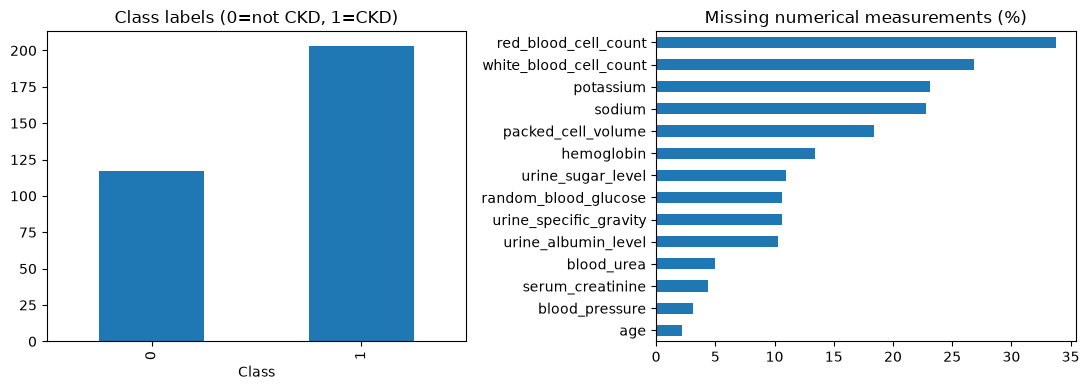

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_full_train["ckd_status"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Class labels (0=not CKD, 1=CKD)")
axes[0].set_xlabel("Class")
df_full_train[numerical].isna().mean().mul(100).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Missing numerical measurements (%)")
plt.tight_layout()
plt.show()


In [52]:
global_ckd = df_full_train["ckd_status"].mean()

print(global_ckd)

0.634375


In [53]:
group_ckd = df_full_train.groupby("hypertension")["ckd_status"].mean()

risk_ratio = group_ckd / global_ckd

print(risk_ratio)


hypertension
no     0.669951
yes    1.576355
Name: ckd_status, dtype: float64


In [54]:
def mutual_info_ckd_score(series):
    return mutual_info_score(series.fillna("missing"), df_full_train["ckd_status"])

mi = df_full_train[catergorical].apply(mutual_info_ckd_score)
mi.sort_values(ascending=False)


ckd_status                 0.656586
red_blood_cell_status      0.259234
hypertension               0.230427
diabetes_mellitus          0.214751
pus_cell_status            0.143998
appetite                   0.131006
pedal_edema                0.103708
anemia                     0.080127
pus_cell_clumps            0.063630
coronary_artery_disease    0.046384
bacteria                   0.035523
dtype: float64

In [ ]:
correlation = df_full_train[numerical].corrwith(
    df_full_train["ckd_status"])

correlation.sort_values(ascending=False)


urine_albumin_level       0.636634
random_blood_glucose      0.405746
blood_urea                0.365331
urine_sugar_level         0.339146
blood_pressure            0.284896
serum_creatinine          0.280050
white_blood_cell_count    0.237625
age                       0.199393
potassium                 0.102881
sodium                   -0.344879
red_blood_cell_count     -0.687925
urine_specific_gravity   -0.724843
packed_cell_volume       -0.741909
hemoglobin               -0.766499
dtype: float64

In [56]:
correlation.abs().sort_values(ascending=False)

hemoglobin                0.766499
packed_cell_volume        0.741909
urine_specific_gravity    0.724843
red_blood_cell_count      0.687925
urine_albumin_level       0.636634
random_blood_glucose      0.405746
blood_urea                0.365331
sodium                    0.344879
urine_sugar_level         0.339146
blood_pressure            0.284896
serum_creatinine          0.280050
white_blood_cell_count    0.237625
age                       0.199393
potassium                 0.102881
dtype: float64

In [60]:
print(numerical)
print(catergorical)

['age', 'blood_pressure', 'urine_specific_gravity', 'urine_albumin_level', 'urine_sugar_level', 'random_blood_glucose', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'hemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count']
['red_blood_cell_status', 'pus_cell_status', 'pus_cell_clumps', 'bacteria', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'pedal_edema', 'anemia', 'ckd_status']


In [ ]:
numerical = [
    col for col in numerical
    if col != "ckd_status"
]

catergorical = [
    col for col in catergorical
    if col != "ckd_status"
]

In [62]:
# Step 1: Fill missing numerical values
medians = df_train[numerical].median()

def prepare(df):
    df = df.copy()

    df[numerical] = df[numerical].fillna(medians)
    df[catergorical] = df[catergorical].astype("string").fillna("missing").astype(str)

    return df.to_dict(orient="records")


# Step 2: Convert data into dictionaries
train_dicts = prepare(df_train)
val_dicts = prepare(df_val)


# Step 3: One-hot encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print(X_train.shape)
print(X_val.shape)


(240, 44)
(80, 44)


In [66]:
import pandas as pd

encoded_df = pd.DataFrame(
    X_train,
    columns=dv.get_feature_names_out()
)

display(encoded_df.head())

,age,anemia=missing,anemia=no,anemia=yes,appetite=good,appetite=missing,appetite=poor,bacteria=missing,bacteria=notpresent,bacteria=present,...,red_blood_cell_count,red_blood_cell_status=abnormal,red_blood_cell_status=missing,red_blood_cell_status=normal,serum_creatinine,sodium,urine_albumin_level,urine_specific_gravity,urine_sugar_level,white_blood_cell_count
0,55.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,4.9,0.0,0.0,1.0,0.5,150.0,0.0,1.020,0.0,6700.0
1,56.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,2.1,0.0,0.0,1.0,13.3,124.0,4.0,1.010,1.0,5400.0
2,8.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,4.8,0.0,0.0,1.0,0.9,138.0,3.0,1.025,0.0,6700.0
3,74.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,4.5,0.0,0.0,1.0,0.6,147.0,0.0,1.020,0.0,6000.0
4,43.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,4.5,0.0,0.0,1.0,1.1,143.0,0.0,1.025,0.0,7800.0


In [67]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print(dv.get_feature_names_out())

display(encoded_df.head())

Training shape: (240, 44)
Validation shape: (80, 44)
['age' 'anemia=missing' 'anemia=no' 'anemia=yes' 'appetite=good'
 'appetite=missing' 'appetite=poor' 'bacteria=missing'
 'bacteria=notpresent' 'bacteria=present' 'blood_pressure' 'blood_urea'
 'coronary_artery_disease=missing' 'coronary_artery_disease=no'
 'coronary_artery_disease=yes' 'diabetes_mellitus=missing'
 'diabetes_mellitus=no' 'diabetes_mellitus=yes' 'hemoglobin'
 'hypertension=missing' 'hypertension=no' 'hypertension=yes'
 'packed_cell_volume' 'pedal_edema=missing' 'pedal_edema=no'
 'pedal_edema=yes' 'potassium' 'pus_cell_clumps=missing'
 'pus_cell_clumps=notpresent' 'pus_cell_clumps=present'
 'pus_cell_status=abnormal' 'pus_cell_status=missing'
 'pus_cell_status=normal' 'random_blood_glucose' 'red_blood_cell_count'
 'red_blood_cell_status=abnormal' 'red_blood_cell_status=missing'
 'red_blood_cell_status=normal' 'serum_creatinine' 'sodium'
 'urine_albumin_level' 'urine_specific_gravity' 'urine_sugar_level'
 'white_blood_ce

,age,anemia=missing,anemia=no,anemia=yes,appetite=good,appetite=missing,appetite=poor,bacteria=missing,bacteria=notpresent,bacteria=present,...,red_blood_cell_count,red_blood_cell_status=abnormal,red_blood_cell_status=missing,red_blood_cell_status=normal,serum_creatinine,sodium,urine_albumin_level,urine_specific_gravity,urine_sugar_level,white_blood_cell_count
0,55.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,4.9,0.0,0.0,1.0,0.5,150.0,0.0,1.020,0.0,6700.0
1,56.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,2.1,0.0,0.0,1.0,13.3,124.0,4.0,1.010,1.0,5400.0
2,8.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,4.8,0.0,0.0,1.0,0.9,138.0,3.0,1.025,0.0,6700.0
3,74.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,4.5,0.0,0.0,1.0,0.6,147.0,0.0,1.020,0.0,6000.0
4,43.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,4.5,0.0,0.0,1.0,1.1,143.0,0.0,1.025,0.0,7800.0


In [63]:
model = LogisticRegression(solver="liblinear", max_iter=1000, random_state=1)
model.fit(X_train, y_train)

y_pred_proba = model.predict_proba(X_val)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

print("Validation accuracy:", round(accuracy_score(y_val, y_pred), 3))
print("Validation recall:", round(recall_score(y_val, y_pred, zero_division=0), 3))
print("Validation ROC-AUC:", round(roc_auc_score(y_val, y_pred_proba), 3))


Validation accuracy: 1.0
Validation recall: 1.0
Validation ROC-AUC: 1.0
